# Asalariados con contrato temporal

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "tasa-temporalidad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Asalariados con contrato temporal"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de los asalariados"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de los asalariados que tienen un contrato de duración determinada (temporal), según las encuestas de población activa.

**Cómo se lee.** Un valor de 20 significa que uno de cada cinco asalariados tiene contrato temporal. Los autónomos no están en el denominador.

**Limitaciones.**
- La reforma laboral de 2021 (Real Decreto-ley 32/2021) limitó los contratos temporales; los contratos fijos discontinuos, que crecieron después, cuentan como indefinidos.
- Lo que se considera contrato temporal depende de la legislación de cada país.
- EE. UU. queda sin dato (decisión de la revisión humana del 2026-10-23): su encuesta no pregunta por el tipo de contrato, sino si el asalariado espera que su empleo dure, y solo se hace algunos años, así que no es el mismo indicador.
- España y la UE-27 son de 15 a 64 años (Eurostat); la OCDE publica la incidencia del empleo temporal de todas las edades, sin el tramo de 15 a 64.

## 2. Descarga

- **España y UE-27:** Eurostat `lfsa_etpgan`: asalariados temporales en % del total de asalariados, de 15 a 64 años, ambos sexos, todas las nacionalidades (`citizen=TOTAL`). El config nombra `lfsa_etpga`, que Eurostat ya no difunde; `lfsa_etpgan` es la misma tabla con el desglose por nacionalidad (anotado en `pending.md`).
- **OCDE y Canadá:** OCDE, empleo según la permanencia del puesto (`OECD.ELS.SAE,DSD_TEMP@DF_TEMP_I`, versión 1.0): asalariados (`ICSE93_1`) con empleo temporal (`EMP_TEMP`), en % de los asalariados, ambos sexos, todas las edades (`_T`; el dataflow no publica el tramo de 15 a 64 años).
- **Solo para las notas:** la serie de España de la OCDE, para compararla con la de Eurostat.
- **EE. UU.:** sin dato; no se descarga (véase la limitación del contexto).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

AREAS_OCDE = {"CAN": "canada", "OECD": "ocde"}
DATAFLOW_TEMP = "OECD.ELS.SAE,DSD_TEMP@DF_TEMP_I,1.0"
# Dimensiones: país . medida . unidad . sexo . edad . situación profesional . frecuencia
CLAVE_TEMP = "{AREA}.EMP_TEMP.PT_POP_SUB._T._T.ICSE93_1.A"
FILTROS_EU = {"citizen": "TOTAL", "age": "Y15-64", "sex": "T", "unit": "PC"}

oc, fuentes_oc = oecd.get(DATAFLOW_TEMP, CLAVE_TEMP, areas=AREAS_OCDE, desde=DESDE)
eu, fuentes_eu = eurostat.get("lfsa_etpgan", FILTROS_EU, desde=DESDE)  # ES y EU27_2020
oc_esp, _ = oecd.get(DATAFLOW_TEMP, CLAVE_TEMP, areas={"ESP": "espana"}, desde=DESDE)  # solo para las notas
print(oc.groupby("serie")["periodo"].agg(["min", "max", "count"]))
print(eu.groupby("serie")["periodo"].agg(["min", "max"]))

         min   max  count
serie                    
canada  1997  2025     29
ocde    1980  2025     46
         min   max
serie             
espana  1995  2025
ue27    2002  2025


## 3. Transformación

1. Las series se usan tal como las publican las fuentes.
2. **Comparación de España** en Eurostat (15 a 64 años) y en la OCDE (todas las edades), para las notas.
3. **EE. UU.:** serie vacía, con el motivo en las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


# EE. UU. sin dato: la OCDE usa para EE. UU. otra definición (ver NOTAS)
vacia = pd.DataFrame({"serie": ["eeuu"], "periodo": [DESDE], "valor": [float("nan")]})
df = pd.concat([eu, oc, vacia], ignore_index=True)
fuente_eeuu = FuenteMeta(
    "eeuu", oecd.ORGANISMO, "sin dato: la OCDE publica para EE. UU. otra definición de empleo temporal",
    oecd.URL_EXPLORER, max(f.fecha_consulta for f in fuentes_oc),
)
fuentes = [*fuentes_eu, *fuentes_oc, fuente_eeuu]
assert df["valor"].dropna().between(0, 100).all(), "porcentaje fuera de rango"

NOTAS = [
    "España y UE-27: Eurostat (lfsa_etpgan), asalariados de 15 a 64 años con contrato temporal en % del total de "
    "asalariados, todas las nacionalidades; UE-27 de composición actual (EU27_2020).",
    "OCDE y Canadá: OCDE, empleo según la permanencia del puesto (DSD_TEMP@DF_TEMP_I): asalariados con empleo "
    "temporal en % del total de asalariados, de todas las edades (la OCDE no publica el tramo de 15 a 64 años).",
    "EE. UU. sin dato: no hay un indicador equivalente. Su encuesta no pregunta por el tipo de contrato y la OCDE usa la "
    "encuesta complementaria sobre empleo eventual (Contingent and Alternative Employment Arrangements), que cuenta como "
    "temporales a los asalariados que no esperan que su empleo dure, a los de empresas de trabajo temporal y a los "
    "autónomos que trabajan para una sola empresa y esperan hacerlo un año o menos, y solo se hace algunos años (OCDE, "
    "LFS Notes and Sources, tabla 3).",
    nota_comparacion("Comparación de España en Eurostat (15 a 64 años) y en la OCDE (todas las edades)",
                     serie(eu, "espana"), serie(oc_esp, "espana")),
    "La reforma laboral de 2021 (Real Decreto-ley 32/2021, de 28 de diciembre) limitó las causas de los contratos "
    "temporales desde 2022; los contratos fijos discontinuos cuentan como indefinidos.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat (lfsa_etpgan), asalariados de 15 a 64 años con contrato temporal en % del total de asalariados, todas las nacionalidades; UE-27 de composición actual (EU27_2020).
- OCDE y Canadá: OCDE, empleo según la permanencia del puesto (DSD_TEMP@DF_TEMP_I): asalariados con empleo temporal en % del total de asalariados, de todas las edades (la OCDE no publica el tramo de 15 a 64 años).
- EE. UU. sin dato: no hay un indicador equivalente. Su encuesta no pregunta por el tipo de contrato y la OCDE usa la encuesta complementaria sobre empleo eventual (Contingent and Alternative Employment Arrangements), que cuenta como temporales a los asalariados que no esperan que su empleo dure, a los de empresas de trabajo temporal y a los autónomos que trabajan para una sola empresa y esperan hacerlo un año o menos, y solo se hace algunos años (OCDE, LFS Notes and Sources, tabla 3).
- Comparación de España en Eurostat (15 a 64 años) y en la OCDE (todas las edades): en los 31 años comune

## 4. Visualización

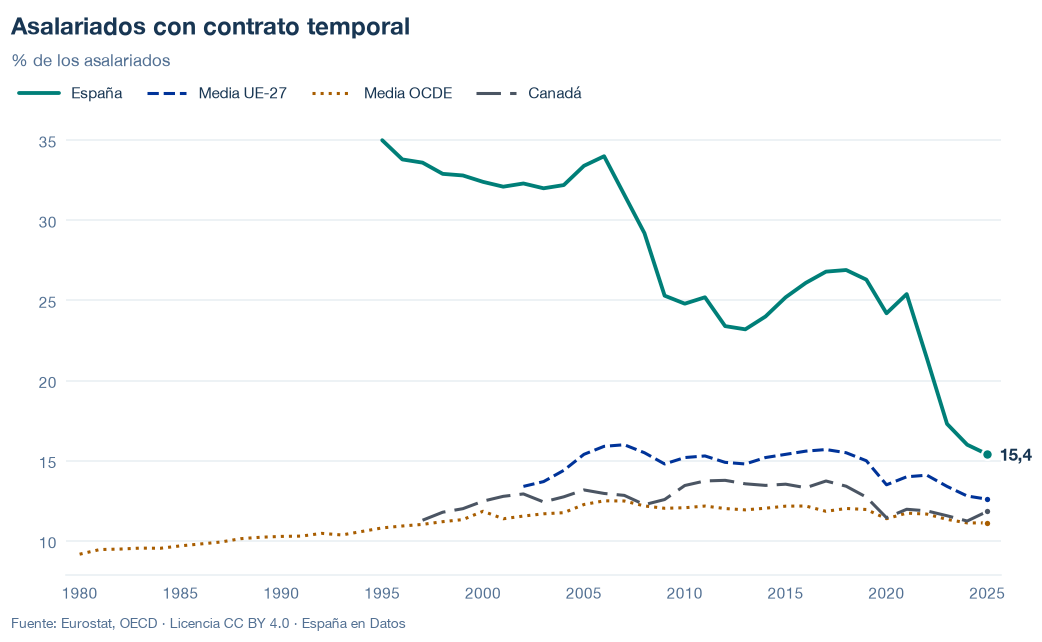

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/tasa-temporalidad.json y data/tasa-temporalidad.csv


## 6. Fuentes, notas y licencia

- Eurostat, `lfsa_etpgan` (`citizen=TOTAL`, `Y15-64`, `T`, `PC`).
- OCDE, empleo según la permanencia del puesto: `OECD.ELS.SAE,DSD_TEMP@DF_TEMP_I,1.0` (`EMP_TEMP`, `PT_POP_SUB`, `_T`, `_T`, `ICSE93_1`, `A`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.